In [187]:
import numpy as np
import scipy
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt

import odrpack as odr

from uncertainties import ufloat
from uncertainties import umath
from uncertainties import unumpy as un

In [188]:
#para meter

inFileName = "datydata.xlsx"

df = {
    "Cu": pd.read_excel(inFileName, sheet_name="coble", decimal = ","),
    "Al": pd.read_excel(inFileName, sheet_name="alimunio", decimal = ","),
    "Air": pd.read_excel(inFileName, sheet_name="aire", decimal = ","),
}

tiempot = {
    "Cu": un.uarray(df["Cu"].to_numpy()[:,0], 10/np.sqrt(12)),
    "Al": un.uarray(df["Al"].to_numpy()[:,0], 10/np.sqrt(12)),
    "Air": un.uarray(df["Air"].to_numpy()[:,0], 10/np.sqrt(12)),
}

temperaturaT = {
    "Cu": un.uarray(df["Cu"].to_numpy()[:,1], 0.01/np.sqrt(12)),
    "Al": un.uarray(df["Al"].to_numpy()[:,1], 0.01/np.sqrt(12)),
    "Air": un.uarray(df["Air"].to_numpy()[:,1], 0.01/np.sqrt(12)),
}

waterMass = {
    "Cu": ufloat(575.8, 0.1/np.sqrt(12)) - ufloat(251.9, 0.1/np.sqrt(12)),
    "Al": ufloat(597.8, 0.1/np.sqrt(12)) - ufloat(251.9, 0.1/np.sqrt(12)),
    "Air": ufloat(575.8, 0.1/np.sqrt(12)) - ufloat(251.9, 0.1/np.sqrt(12)),
}

waterHeatCapacity = 4.184

calorimeterCapacity = ufloat(184,6)

crossSectionS = 4.91e-4

distanciaTerminales = {
    "Cu": ufloat(25.45e-2, 0.01e-2/np.sqrt(12)),
    "Al": ufloat(25.4e-2, 0.01e-2/np.sqrt(12)),
}

In [189]:
p = {}
beta = {}
portion = slice(7,None)

for experimento in {"Cu", "Al", "Air"}:

    X = tiempot[experimento][portion]
    Y = temperaturaT[experimento][portion]

    #=============================== Blocón de ODR_FIT ===============================

    def func(x, beta):
        return beta[0] * x + beta[1]

    beta0 = [0.03,0]

    fittingX = un.nominal_values(X)
    fittingY = un.nominal_values(Y)
    fittingXUncertainty = un.std_devs(X)
    fittingYUncertainty = un.std_devs(Y)

    sol = odr.odr_fit(func, fittingX, fittingY, beta0, weight_x = 1/(fittingXUncertainty**2), weight_y = 1/(fittingYUncertainty**2))

    pendiente = ufloat(sol.beta[0],sol.sd_beta[0])#np.sqrt(sol.cov_beta[0,0]))
    ordenada = ufloat(sol.beta[1],sol.sd_beta[1])#np.sqrt(sol.cov_beta[1,1]))

    print("pendiente = {:.3e}".format(pendiente))
    print("ordenada = {:.5e}".format(ordenada))

    print(f"χ² reducido = {sol.sum_square/(len(un.nominal_values(X))-len(sol.beta))}")
    #print(f"pearson = {scipy.stats.pearsonr(fittingX, fittingY).statistic}")
    print(f"R² = {scipy.stats.pearsonr(fittingX, fittingY).statistic**2}")

    #=================================================================================

    beta[experimento] = sol.beta
    p[experimento] = pendiente

pendiente = (5.718+/-0.229)e-03
ordenada = (2.74539+/-0.00059)e+02
χ² reducido = 0.8395022601435631
R² = 0.9967956366115619
pendiente = (7.003+/-0.105)e-03
ordenada = (2.75424+/-0.00027)e+02
χ² reducido = 0.11994775569807203
R² = 0.999546690843156
pendiente = (3.889+/-0.025)e-03
ordenada = (2.72348+/-0.00010)e+02
χ² reducido = 0.9180156041307637
R² = 0.9995219955195959


In [190]:
dQdt = {
    "Cu": p["Cu"] * (waterMass["Cu"] * waterHeatCapacity + calorimeterCapacity),
    "Al": p["Al"] * (waterMass["Al"] * waterHeatCapacity + calorimeterCapacity),
    "Air": p["Air"] * (waterMass["Air"] * waterHeatCapacity + calorimeterCapacity),
}

dTdx = {
    "Cu": 33.88095238 / distanciaTerminales["Cu"],
    "Al": 13.54285714 / distanciaTerminales["Al"],
}

kappa = {
    "Cu": - (dQdt["Air"] - dQdt["Cu"]) / (crossSectionS * dTdx["Cu"]),
    "Al": - (dQdt["Air"] - dQdt["Al"]) / (crossSectionS * dTdx["Al"]),
}

print(kappa)

{'Cu': 73.33133939632965+/-2.5658067664153275, 'Al': 127.62558920294872+/-14.35583741354189}


# Fin de cuentas

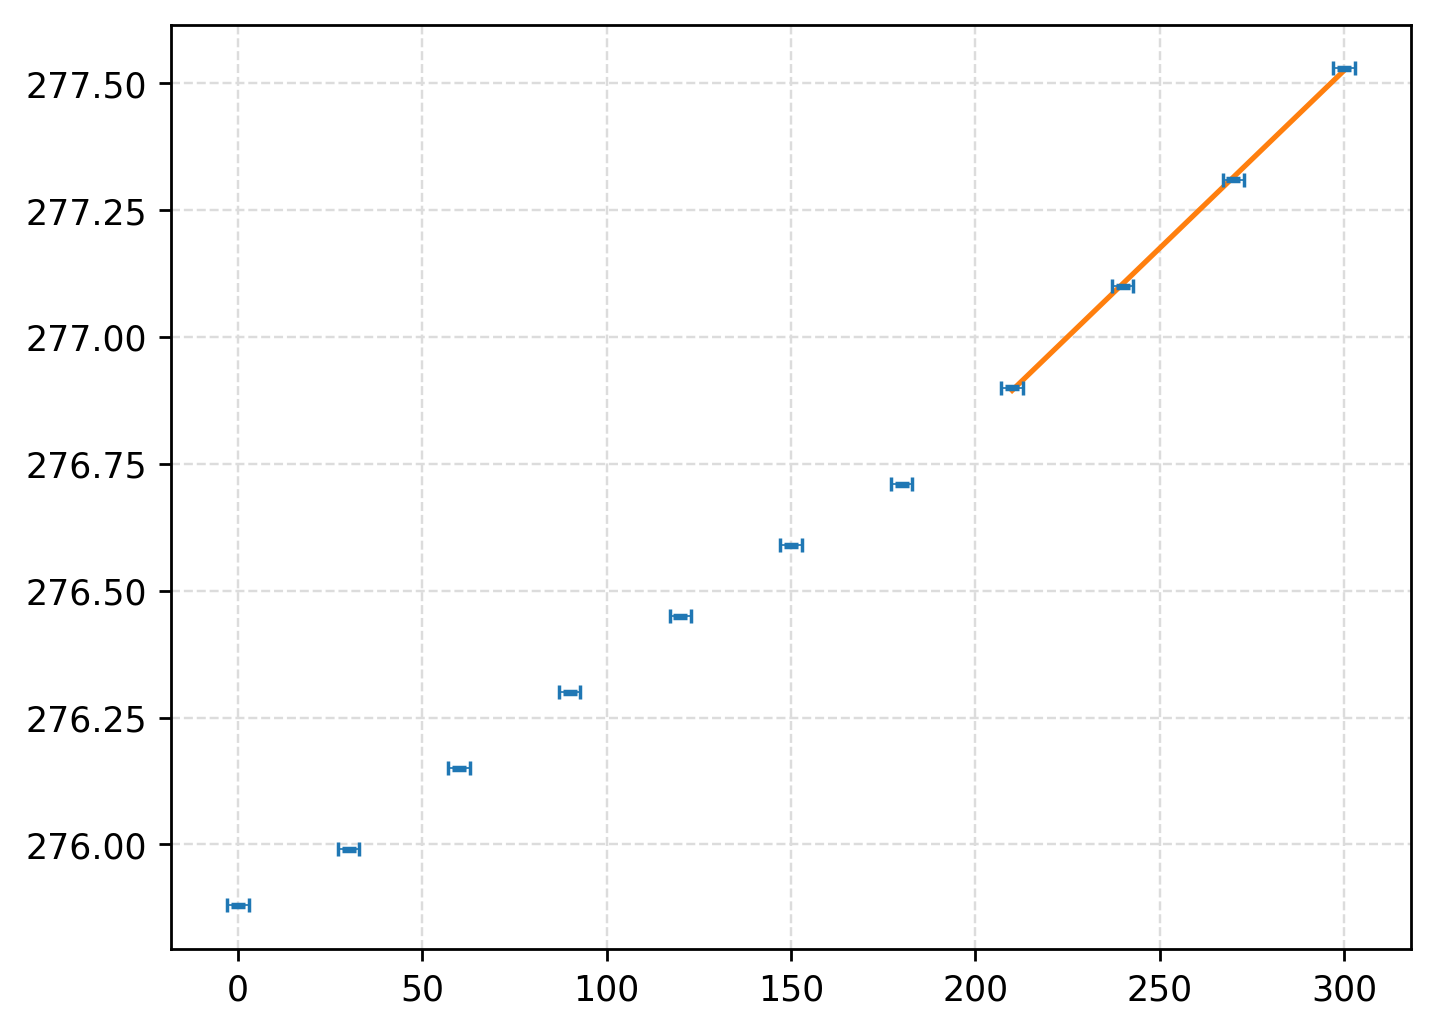

In [191]:
experimento = "Cu"

X = tiempot[experimento]
Y = temperaturaT[experimento]


fig, ax = plt.subplots(dpi = 250)

ax.errorbar(x = un.nominal_values(X), y = un.nominal_values(Y), xerr = un.std_devs(X), yerr = un.std_devs(Y),label=experimento, ls = "", marker = "", markersize = 2, capsize=2, zorder = 10, elinewidth=.5)

ax.plot(un.nominal_values(X[portion]), func(un.nominal_values(X[portion]), beta[experimento]))

ax.grid(zorder=0,color='gainsboro', linestyle='--', linewidth=0.7)

plt.show()